In [1]:
!pip install -q kagglehub mediapipe
!wget -q -O hand_landmarker.task https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/latest/hand_landmarker.task

import glob, os, re, time
import numpy as np
import matplotlib.pyplot as plt
import cv2
import torch
import kagglehub
import mediapipe as mp
from mediapipe.tasks import python as mp_tasks
from mediapipe.tasks.python import vision

path = kagglehub.dataset_download("grassknoted/asl-alphabet")
detector = vision.HandLandmarker.create_from_options(vision.HandLandmarkerOptions(
    base_options=mp_tasks.BaseOptions(model_asset_path="hand_landmarker.task"),
    running_mode=vision.RunningMode.IMAGE,
    num_hands=1,
    min_hand_detection_confidence=0.3,
))
LETTERS = list("ABCDEFGHIKLMNOPQRSTUVWXY")

def letter_files(letter):
    files = glob.glob(f"{path}/**/asl_alphabet_train/{letter}/*.jpg", recursive=True)
    return sorted(files, key=lambda p: int(re.findall(r"\d+", os.path.basename(p))[0]))

def crop_hand(rgb, landmarks, size=64):
    h, w = rgb.shape[:2]
    xs = np.array([lm.x for lm in landmarks]) * w
    ys = np.array([lm.y for lm in landmarks]) * h
    cx, cy = (xs.min() + xs.max()) / 2, (ys.min() + ys.max()) / 2
    side = max(xs.max() - xs.min(), ys.max() - ys.min()) * 1.3
    pad = int(side) + 1
    padded = cv2.copyMakeBorder(rgb, pad, pad, pad, pad, cv2.BORDER_CONSTANT, value=0)
    x0, y0 = int(cx - side / 2) + pad, int(cy - side / 2) + pad
    s = int(side)
    return cv2.resize(padded[y0:y0 + s, x0:x0 + s], (size, size))

def extract_v2(files):
    lms_out, crops, frames = [], [], []
    for f in files:
        rgb = cv2.cvtColor(cv2.imread(f), cv2.COLOR_BGR2RGB)
        res = detector.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb))
        if res.hand_landmarks:
            lms = res.hand_landmarks[0]
            lms_out.append([[lm.x, lm.y, lm.z] for lm in lms])
            crops.append(crop_hand(rgb, lms))
            frames.append(int(re.findall(r"\d+", os.path.basename(f))[0]))
    return lms_out, crops, frames

print("GPU:", torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")
print("A photos:", len(letter_files("A")))
print("Setup ready ✅")

Using Colab cache for faster access to the 'asl-alphabet' dataset.
GPU: True Tesla T4
A photos: 3000
Setup ready ✅


A: train 340/400  test  43/120   (67s)
B: train 337/400  test  32/120   (135s)
C: train 334/400  test  32/120   (200s)
D: train 380/400  test  57/120   (266s)
E: train 351/400  test  41/120   (331s)
F: train 384/400  test 119/120   (398s)
G: train 372/400  test  64/120   (463s)
H: train 391/400  test  35/120   (531s)
I: train 389/400  test  34/120   (590s)
K: train 390/400  test  78/120   (611s)
L: train 380/400  test  71/120   (669s)
M: train 286/400  test  33/120   (689s)
N: train 235/400  test  27/120   (745s)
O: train 382/400  test  52/120   (767s)
P: train 356/400  test  20/120   (823s)
Q: train 383/400  test  31/120   (845s)
R: train 380/400  test  67/120   (904s)
S: train 389/400  test  71/120   (929s)
T: train 383/400  test  32/120   (986s)
U: train 370/400  test  63/120   (1010s)
V: train 364/400  test  78/120   (1067s)
W: train 362/400  test  73/120   (1091s)
X: train 366/400  test  29/120   (1146s)
Y: train 397/400  test  51/120   (1171s)

train_lms    (8701, 21, 3)
train_cr

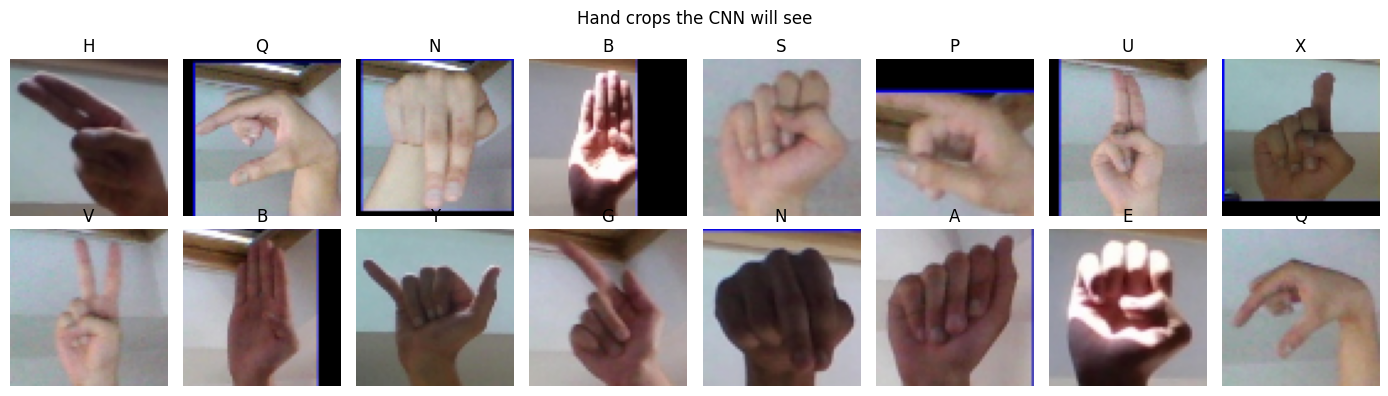

In [2]:
data = {s: {"lms": [], "crops": [], "y": [], "frame": []} for s in ["train", "test"]}
start = time.time()

for label, letter in enumerate(LETTERS):
    files = letter_files(letter)
    counts = []
    for split, chosen in [("train", files[0:2000:5]), ("test", files[2400:3000:5])]:
        l, c, f = extract_v2(chosen)
        data[split]["lms"] += l
        data[split]["crops"] += c
        data[split]["frame"] += f
        data[split]["y"] += [label] * len(l)
        counts.append(len(l))
    print(f"{letter}: train {counts[0]:3d}/400  test {counts[1]:3d}/120   ({time.time() - start:.0f}s)")

arrays = {}
for s in data:
    arrays[f"{s}_lms"]   = np.array(data[s]["lms"], dtype=np.float32)
    arrays[f"{s}_crops"] = np.array(data[s]["crops"], dtype=np.uint8)
    arrays[f"{s}_y"]     = np.array(data[s]["y"])
    arrays[f"{s}_frame"] = np.array(data[s]["frame"])
np.savez_compressed("day5_data.npz", **arrays)

print()
for k, v in arrays.items():
    print(f"{k:12s} {v.shape}")

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
idx = np.random.default_rng(0).choice(len(arrays["train_y"]), 16, replace=False)
for ax, i in zip(axes.flat, idx):
    ax.imshow(arrays["train_crops"][i]); ax.set_title(LETTERS[arrays["train_y"][i]]); ax.axis("off")
plt.suptitle("Hand crops the CNN will see"); plt.tight_layout()
plt.savefig("day5_crops.png"); plt.show()

Saving my_hands.npz to my_hands (1).npz
train      6839 photos   letters: 24
val        1399 photos   letters: 24
test       1233 photos   letters: 24
my_hands    360 photos   letters: 24


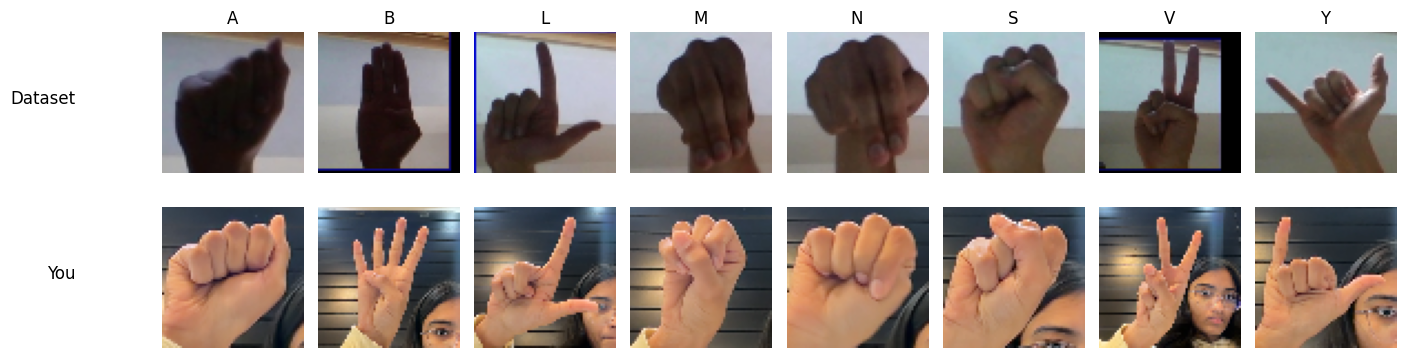

In [8]:
from google.colab import files
uploaded = files.upload()

ASPECT = 1920 / 1080

mine = np.load("my_hands.npz")
my_lms, my_crops, my_y = mine["lms"], mine["crops"], mine["y"]

d = np.load("day5_data.npz")
is_train = d["train_frame"] <= 1600
is_val   = d["train_frame"] > 1700

splits = {
    "train":    (d["train_lms"][is_train], d["train_crops"][is_train], d["train_y"][is_train], 1.0),
    "val":      (d["train_lms"][is_val],   d["train_crops"][is_val],   d["train_y"][is_val],   1.0),
    "test":     (d["test_lms"],            d["test_crops"],            d["test_y"],            1.0),
    "my_hands": (my_lms,                   my_crops,                   my_y,                   ASPECT),
}
for name, (l, c, y, a) in splits.items():
    print(f"{name:9s} {len(y):5d} photos   letters: {len(set(y.tolist()))}")

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for col, letter in enumerate(["A", "B", "L", "M", "N", "S", "V", "Y"]):
    k = LETTERS.index(letter)
    ds = np.where(splits["train"][2] == k)[0]
    me = np.where(my_y == k)[0]
    if len(ds): axes[0, col].imshow(splits["train"][1][ds[0]])
    if len(me): axes[1, col].imshow(my_crops[me[0]])
    axes[0, col].set_title(letter); axes[0, col].axis("off"); axes[1, col].axis("off")
axes[0, 0].text(-40, 32, "Dataset", fontsize=12, ha="right")
axes[1, 0].text(-40, 32, "You", fontsize=12, ha="right")
plt.tight_layout(); plt.savefig("day5_dataset_vs_me.png"); plt.show()

In [9]:
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
device = "cuda" if torch.cuda.is_available() else "cpu"

def make_features(lms, aspect=1.0, use_z=False, mirror=False):
    pts = lms.copy()
    pts[:, :, 0] *= aspect
    pts[:, :, 2] *= aspect
    if mirror:
        pts[:, :, 0] *= -1
    pts = pts - pts[:, :1, :]
    pts = pts / np.abs(pts[:, :, :2]).max(axis=(1, 2), keepdims=True)
    if not use_z:
        pts = pts[:, :, :2]
    return pts.reshape(len(pts), -1).astype(np.float32)

class LandmarkMLP(nn.Module):
    def __init__(self, n_in, n_classes=24, dropout=0.0):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_in, 128), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(128, 64),   nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(64, n_classes),
        )

    def forward(self, x):
        return self.net(x)

def train_mlp(use_z=False, dropout=0.0, mirror_aug=False, epochs=40, seed=0):
    torch.manual_seed(seed)
    l, _, y, a = splits["train"]
    X = make_features(l, a, use_z)
    Y = y
    if mirror_aug:
        X = np.concatenate([X, make_features(l, a, use_z, mirror=True)])
        Y = np.concatenate([y, y])
    loader = DataLoader(TensorDataset(torch.from_numpy(X), torch.from_numpy(Y).long()),
                        batch_size=64, shuffle=True)
    model = LandmarkMLP(X.shape[1], dropout=dropout).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    loss_fn = nn.CrossEntropyLoss()
    for epoch in range(epochs):
        model.train()
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            loss = loss_fn(model(xb), yb)
            opt.zero_grad()
            loss.backward()
            opt.step()
    return model

def predict(model, split, use_z):
    l, _, y, a = splits[split]
    X = torch.from_numpy(make_features(l, a, use_z)).to(device)
    model.eval()
    with torch.no_grad():
        return model(X).argmax(dim=1).cpu().numpy()

def accuracy(model, split, use_z):
    return (predict(model, split, use_z) == splits[split][2]).mean()

experiments = {
    "1 baseline (Day 4 model)": dict(use_z=False, dropout=0.0, mirror_aug=False),
    "2 + dropout":              dict(use_z=False, dropout=0.3, mirror_aug=False),
    "3 + dropout + mirror":     dict(use_z=False, dropout=0.3, mirror_aug=True),
    "4 + dropout + mirror + z": dict(use_z=True,  dropout=0.3, mirror_aug=True),
}
models = {}
print(f"{'Experiment':27s} {'train':>7s} {'val':>7s}")
for name, cfg in experiments.items():
    t = time.time()
    m = train_mlp(**cfg)
    models[name] = (m, cfg)
    print(f"{name:27s} {accuracy(m, 'train', cfg['use_z']):7.1%} {accuracy(m, 'val', cfg['use_z']):7.1%}   ({time.time() - t:.0f}s)")

Experiment                    train     val
1 baseline (Day 4 model)      99.2%   97.7%   (9s)
2 + dropout                   98.3%   97.4%   (9s)
3 + dropout + mirror          98.4%   96.9%   (20s)
4 + dropout + mirror + z      98.5%   95.1%   (19s)


In [5]:
final_cfg = dict(use_z=False, dropout=0.0, mirror_aug=True)
final = train_mlp(**final_cfg)
models["5 FINAL: baseline + mirror"] = (final, final_cfg)

print(f"{'Model':27s} {'val':>7s} {'test':>7s} {'MY HANDS':>9s}")
for name, (m, cfg) in models.items():
    z = cfg["use_z"]
    print(f"{name:27s} {accuracy(m, 'val', z):7.1%} {accuracy(m, 'test', z):7.1%} {accuracy(m, 'my_hands', z):9.1%}")

base = models["1 baseline (Day 4 model)"][0]
l, _, y, _ = splits["my_hands"]
with torch.no_grad():
    base.eval()
    p = base(torch.from_numpy(make_features(l, 1.0, False)).to(device)).argmax(1).cpu().numpy()
print(f"\nBaseline on my hands WITHOUT aspect fix (Day 4 bug): {(p == y).mean():.1%}")

from collections import Counter
mp_pred = predict(final, "my_hands", False)
print("\nFINAL on my hands, per letter (worst first):")
rows = [(L, (mp_pred[y == k] == k).mean()) for k, L in enumerate(LETTERS) if (y == k).any()]
for L, acc in sorted(rows, key=lambda r: r[1])[:10]:
    print(f"  {L}: {acc:.0%}")
print("\nTop confusions on my hands (true → predicted):")
for (t, pr), n in Counter((LETTERS[t], LETTERS[pr]) for t, pr in zip(y, mp_pred) if t != pr).most_common(8):
    print(f"  {t} → {pr}: {n}")

Model                           val    test  MY HANDS
1 baseline (Day 4 model)      97.7%   90.1%     36.4%
2 + dropout                   97.4%   91.2%     35.6%
3 + dropout + mirror          96.9%   89.6%     38.9%
4 + dropout + mirror + z      95.1%   87.5%     37.8%
5 FINAL: baseline + mirror    96.6%   88.5%     42.8%

Baseline on my hands WITHOUT aspect fix (Day 4 bug): 30.8%

FINAL on my hands, per letter (worst first):
  E: 0%
  G: 0%
  H: 0%
  K: 0%
  M: 0%
  N: 0%
  O: 0%
  P: 0%
  T: 0%
  X: 0%

Top confusions on my hands (true → predicted):
  H → Q: 15
  K → L: 15
  O → Q: 15
  G → F: 14
  N → S: 14
  M → E: 12
  T → S: 12
  D → P: 11


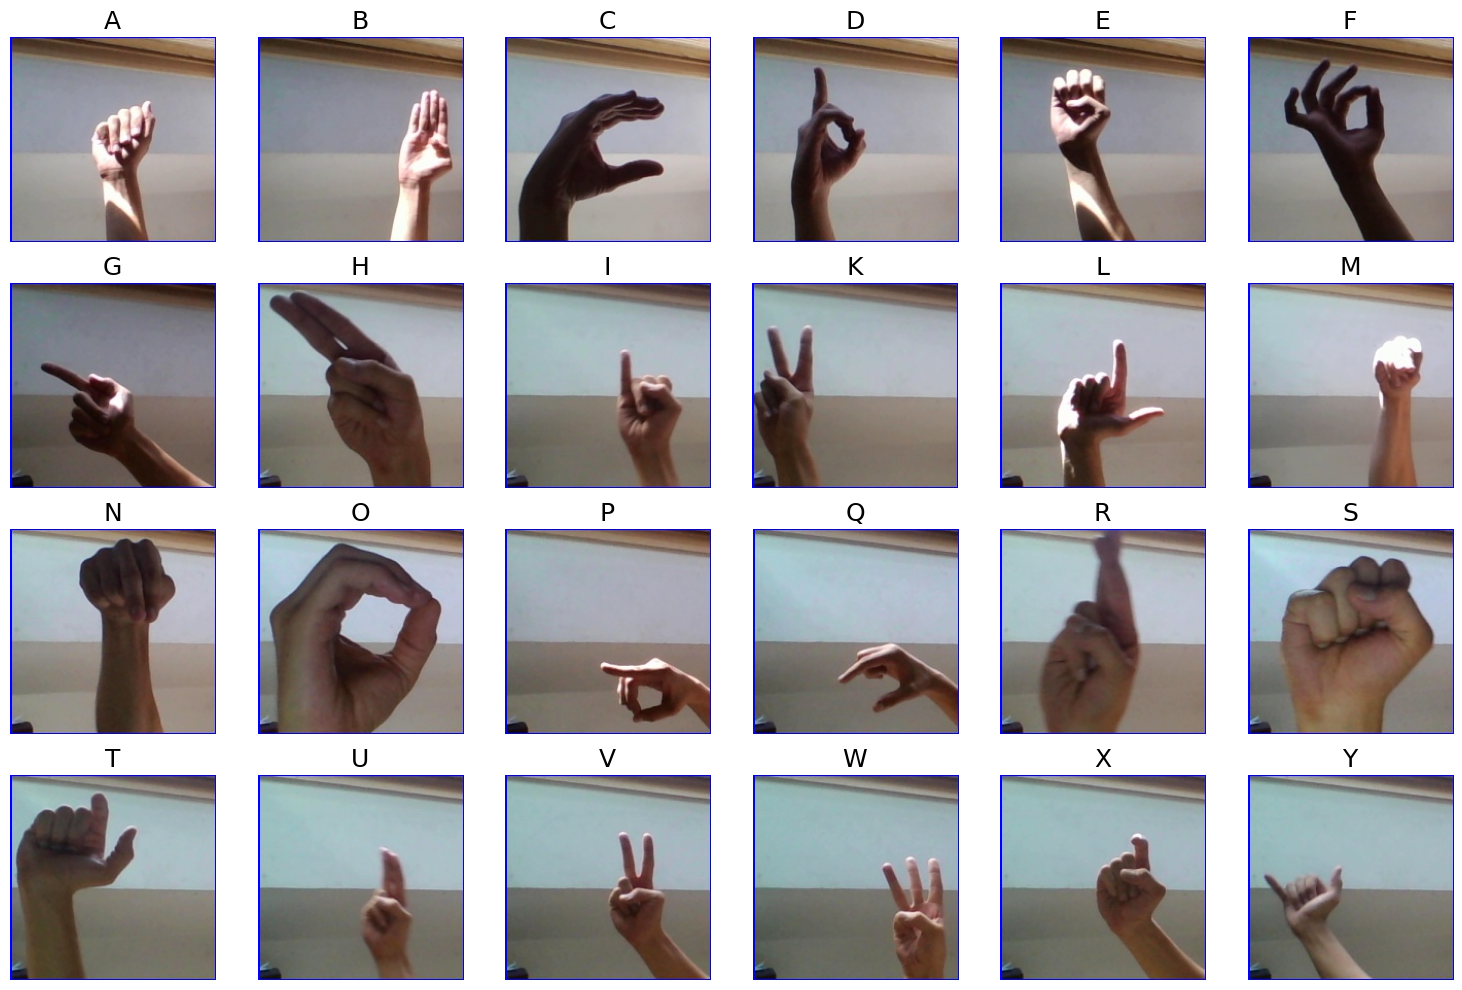

In [6]:
fig, axes = plt.subplots(4, 6, figsize=(15, 10))
for ax, L in zip(axes.flat, LETTERS):
    ax.imshow(plt.imread(letter_files(L)[500]))
    ax.set_title(L, fontsize=18); ax.axis("off")
plt.tight_layout(); plt.savefig("day5_reference.png"); plt.show()

In [10]:
!ls -la my_hands*

import glob
newest = max(glob.glob("my_hands*.npz"), key=os.path.getmtime)
print("Using:", newest)

mine = np.load(newest)
my_lms, my_crops, my_y = mine["lms"], mine["crops"], mine["y"]
splits["my_hands"] = (my_lms, my_crops, my_y, ASPECT)
print("my_hands photos:", len(my_y), "  letters:", len(set(my_y.tolist())))

-rw-r--r-- 1 root root 3898643 Nov 13 19:13 'my_hands (1).npz'
-rw-r--r-- 1 root root 3922797 Nov 13 18:43  my_hands.npz
Using: my_hands (1).npz
my_hands photos: 360   letters: 24


In [11]:
final_cfg = dict(use_z=False, dropout=0.0, mirror_aug=True)
final = train_mlp(**final_cfg)
models["5 FINAL: baseline + mirror"] = (final, final_cfg)

print(f"{'Model':27s} {'val':>7s} {'test':>7s} {'MY HANDS':>9s}")
for name, (m, cfg) in models.items():
    z = cfg["use_z"]
    print(f"{name:27s} {accuracy(m, 'val', z):7.1%} {accuracy(m, 'test', z):7.1%} {accuracy(m, 'my_hands', z):9.1%}")

base = models["1 baseline (Day 4 model)"][0]
l, _, y, _ = splits["my_hands"]
with torch.no_grad():
    base.eval()
    p = base(torch.from_numpy(make_features(l, 1.0, False)).to(device)).argmax(1).cpu().numpy()
print(f"\nBaseline on my hands WITHOUT aspect fix (Day 4 bug): {(p == y).mean():.1%}")

from collections import Counter
mp_pred = predict(final, "my_hands", False)
print("\nFINAL on my hands, per letter (worst first):")
rows = [(L, (mp_pred[y == k] == k).mean()) for k, L in enumerate(LETTERS) if (y == k).any()]
for L, acc in sorted(rows, key=lambda r: r[1])[:10]:
    print(f"  {L}: {acc:.0%}")
print("\nTop confusions on my hands (true → predicted):")
for (t, pr), n in Counter((LETTERS[t], LETTERS[pr]) for t, pr in zip(y, mp_pred) if t != pr).most_common(8):
    print(f"  {t} → {pr}: {n}")

Model                           val    test  MY HANDS
1 baseline (Day 4 model)      97.7%   90.1%     64.7%
2 + dropout                   97.4%   91.2%     65.8%
3 + dropout + mirror          96.9%   89.6%     77.8%
4 + dropout + mirror + z      95.1%   87.5%     76.9%
5 FINAL: baseline + mirror    96.6%   88.5%     80.0%

Baseline on my hands WITHOUT aspect fix (Day 4 bug): 61.7%

FINAL on my hands, per letter (worst first):
  D: 0%
  G: 0%
  K: 0%
  F: 33%
  M: 40%
  T: 53%
  O: 93%
  A: 100%
  B: 100%
  C: 100%

Top confusions on my hands (true → predicted):
  D → P: 15
  G → L: 15
  K → V: 15
  M → N: 9
  T → L: 7
  F → W: 5
  F → Y: 2
  F → L: 2


In [12]:
def to_tensor(crops):
    return torch.from_numpy(crops).permute(0, 3, 1, 2).contiguous()

def augment(x):
    flip = torch.rand(len(x), device=x.device) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)
    bright = torch.empty(len(x), 1, 1, 1, device=x.device).uniform_(0.6, 1.4)
    shift  = torch.empty(len(x), 1, 1, 1, device=x.device).uniform_(-0.15, 0.15)
    return (x * bright + shift).clamp(0, 1)

class SmallCNN(nn.Module):
    def __init__(self, n_classes=24):
        super().__init__()
        def block(c_in, c_out):
            return nn.Sequential(
                nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(),
                nn.Conv2d(c_out, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(),
                nn.MaxPool2d(2),
            )
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, n_classes))

    def forward(self, x):
        return self.head(self.features(x))

def cnn_predict(model, crops):
    model.eval()
    X = to_tensor(crops).to(device)
    out = []
    with torch.no_grad():
        for i in range(0, len(X), 512):
            out.append(model(X[i:i + 512].float() / 255).argmax(dim=1).cpu())
    return torch.cat(out).numpy()

def cnn_acc(model, split):
    return (cnn_predict(model, splits[split][1]) == splits[split][2]).mean()

torch.manual_seed(0)
cnn = SmallCNN().to(device)
print("CNN parameters:", sum(p.numel() for p in cnn.parameters()))

Xtr = to_tensor(splits["train"][1]).to(device)
ytr = torch.from_numpy(splits["train"][2]).long().to(device)
opt = torch.optim.Adam(cnn.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()

start = time.time()
for epoch in range(20):
    cnn.train()
    perm = torch.randperm(len(Xtr), device=device)
    total = 0.0
    for i in range(0, len(perm), 128):
        idx = perm[i:i + 128]
        xb = augment(Xtr[idx].float() / 255)
        loss = loss_fn(cnn(xb), ytr[idx])
        opt.zero_grad()
        loss.backward()
        opt.step()
        total += loss.item() * len(idx)
    print(f"epoch {epoch + 1:2d}  loss {total / len(Xtr):.3f}  val {cnn_acc(cnn, 'val'):.1%}  ({time.time() - start:.0f}s)")

CNN parameters: 291000
epoch  1  loss 2.549  val 25.6%  (7s)
epoch  2  loss 1.564  val 30.0%  (11s)
epoch  3  loss 0.980  val 57.0%  (14s)
epoch  4  loss 0.652  val 84.3%  (18s)
epoch  5  loss 0.458  val 87.9%  (21s)
epoch  6  loss 0.338  val 83.6%  (25s)
epoch  7  loss 0.254  val 91.9%  (29s)
epoch  8  loss 0.195  val 90.8%  (32s)
epoch  9  loss 0.161  val 75.0%  (36s)
epoch 10  loss 0.127  val 93.3%  (39s)
epoch 11  loss 0.120  val 88.5%  (43s)
epoch 12  loss 0.102  val 89.9%  (46s)
epoch 13  loss 0.094  val 88.3%  (49s)
epoch 14  loss 0.085  val 91.0%  (53s)
epoch 15  loss 0.077  val 94.3%  (56s)
epoch 16  loss 0.063  val 91.7%  (60s)
epoch 17  loss 0.054  val 94.1%  (63s)
epoch 18  loss 0.052  val 90.4%  (66s)
epoch 19  loss 0.051  val 96.0%  (70s)
epoch 20  loss 0.047  val 96.1%  (73s)


In [13]:
def ms_per_photo(model, x, n=200):
    model.eval()
    with torch.no_grad():
        for _ in range(10):
            model(x)
        t = time.time()
        for _ in range(n):
            model(x)
    return (time.time() - t) / n * 1000

mlp_cpu = LandmarkMLP(42); mlp_cpu.load_state_dict(final.state_dict())
cnn_cpu = SmallCNN();      cnn_cpu.load_state_dict(cnn.state_dict())
mlp_ms = ms_per_photo(mlp_cpu, torch.rand(1, 42))
cnn_ms = ms_per_photo(cnn_cpu, torch.rand(1, 3, 64, 64))

y = splits["my_hands"][2]
cnn_my = cnn_predict(cnn, splits["my_hands"][1])
n_mlp = sum(p.numel() for p in final.parameters())
n_cnn = sum(p.numel() for p in cnn.parameters())

print(f"{'Model':22s} {'val':>6s} {'test':>6s} {'MY HANDS':>9s} {'params':>8s} {'ms/photo (CPU)':>15s}")
print(f"{'Landmark MLP (final)':22s} {accuracy(final, 'val', False):6.1%} {accuracy(final, 'test', False):6.1%} "
      f"{(mp_pred == y).mean():9.1%} {n_mlp:8,d} {mlp_ms:15.3f}")
print(f"{'Small CNN':22s} {cnn_acc(cnn, 'val'):6.1%} {cnn_acc(cnn, 'test'):6.1%} "
      f"{(cnn_my == y).mean():9.1%} {n_cnn:8,d} {cnn_ms:15.3f}")

print("\nMy hands, letters where either model misses:")
print("  letter   MLP    CNN")
for k, L in enumerate(LETTERS):
    m = y == k
    if m.any() and ((mp_pred[m] != k).any() or (cnn_my[m] != k).any()):
        print(f"    {L}     {(mp_pred[m] == k).mean():4.0%}   {(cnn_my[m] == k).mean():4.0%}")

print("\nCNN top confusions on my hands (true → predicted):")
for (t, p), n in Counter((LETTERS[t], LETTERS[p]) for t, p in zip(y, cnn_my) if t != p).most_common(8):
    print(f"  {t} → {p}: {n}")

Model                     val   test  MY HANDS   params  ms/photo (CPU)
Landmark MLP (final)    96.6%  88.5%     80.0%   15,320           0.059
Small CNN               96.1%  55.5%      8.3%  291,000          10.063

My hands, letters where either model misses:
  letter   MLP    CNN
    A     100%     0%
    B     100%     0%
    C     100%     0%
    D       0%     0%
    E     100%     0%
    F      33%     0%
    G       0%     0%
    H     100%     0%
    I     100%     0%
    K       0%     0%
    L     100%     0%
    M      40%     0%
    O      93%     0%
    Q     100%     0%
    R     100%     0%
    S     100%     0%
    T      53%     0%
    U     100%     0%
    V     100%     0%
    W     100%     0%
    X     100%     0%
    Y     100%     0%

CNN top confusions on my hands (true → predicted):
  A → P: 15
  C → P: 15
  D → P: 15
  G → P: 15
  H → P: 15
  I → P: 15
  L → P: 15
  M → N: 15


In [14]:
sd = {k: v.cpu().numpy() for k, v in final.state_dict().items()}
np.savez("asl_mlp_v2.npz", letters=np.array(LETTERS),
         w1=sd["net.0.weight"], b1=sd["net.0.bias"],
         w2=sd["net.3.weight"], b2=sd["net.3.bias"],
         w3=sd["net.6.weight"], b3=sd["net.6.bias"])

w = np.load("asl_mlp_v2.npz")
def np_forward(x):
    h = np.maximum(0, x @ w["w1"].T + w["b1"])
    h = np.maximum(0, h @ w["w2"].T + w["b2"])
    return h @ w["w3"].T + w["b3"]

X_my = make_features(splits["my_hands"][0], ASPECT, use_z=False)
print(f"NumPy v2 on my hands: {(np_forward(X_my).argmax(1) == splits['my_hands'][2]).mean():.1%}  (should be 80.0%)")

NumPy v2 on my hands: 80.0%  (should be 80.0%)
